In [151]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures    # 다항특성 자동생성 라이브러리
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [152]:
#데이터
df =pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [153]:
# 무게 데이터,정답
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [154]:
# 데이터 전처리
# 학습데이터,테스트 데이터 분리
train_data,test_data,train_label,test_label =\
    train_test_split(df, perch_weight,random_state=42)
train_data[:2]

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [155]:
# 특성값 추가
# include_bias - 기본값 1은 제외
poly = PolynomialFeatures(degree=17,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [156]:
train_poly

array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, ...,
        4.62412954e+08, 2.73489374e+08, 1.61752470e+08],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, ...,
        5.45625431e+09, 3.26632911e+09, 1.95535348e+09],
       [1.87000000e+01, 5.20000000e+00, 3.12000000e+00, ...,
        6.98756076e+08, 4.19253646e+08, 2.51552188e+08],
       ...,
       [2.56000000e+01, 6.56000000e+00, 4.24000000e+00, ...,
        1.10737707e+11, 7.15743718e+10, 4.62614842e+10],
       [4.20000000e+01, 1.28000000e+01, 6.87000000e+00, ...,
        5.87179649e+14, 3.15150327e+14, 1.69147090e+14],
       [3.45000000e+01, 1.02600000e+01, 6.39000000e+00, ...,
        1.27293900e+14, 7.92795345e+13, 4.93758504e+13]], shape=(42, 1139))

In [157]:
poly.get_feature_names_out()

array(['length', ' height', ' width', ..., ' height^2  width^15',
       ' height  width^16', ' width^17'], shape=(1139,), dtype=object)

In [158]:
# 표준점수를 맞추기 위한 규제, 정규화 작업
ss = StandardScaler() 
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [159]:
lasso = Lasso()
lasso.fit(train_scaled,train_label)
score = lasso.score(train_scaled,train_label)
score2 = lasso.score(test_scaled,test_label)
print('train정확도:',score)
print('test정확도:',score2)

train정확도: 0.9923931985141939
test정확도: 0.9956813582095747


In [160]:
#규제의 강도를 높여서 확인
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []
for alpha in alpha_list:
    lasso = Lasso(alpha=alpha)
    lasso.fit(train_scaled,train_label)
    score = lasso.score(train_scaled,train_label)
    score2 = lasso.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)

c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.433673e+03, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.153852e+03, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.483913e+03, tolerance: 5.183e+02
  model = cd_f

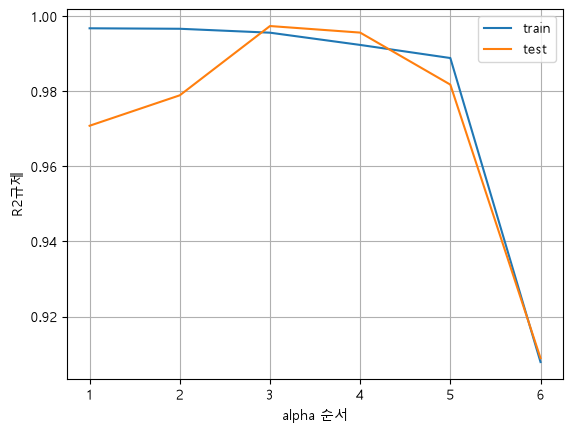

In [161]:
# 선그래프
no_list = list(range(1,7))
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.grid()
plt.legend(['train','test'])
plt.xlabel('alpha 순서')
plt.ylabel('R2규제')
plt.show()

In [162]:
lasso = Lasso(alpha=10)
lasso.fit(train_scaled,train_label)
score= lasso.score(train_scaled,train_label)
score2= lasso.score(test_scaled,test_label)
print('train정확도 : ',score)
print('test정확도 : ',score2)
print(np.sum(lasso.coef_))  #사용하지 않는특성


train정확도 :  0.9889016038328621
test정확도 :  0.9818146166953897
342.63364300683327


In [163]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train정확도 : ',score)
print('test정확도 : ',score2)

train정확도 :  0.9378712937807022
test정확도 :  -1.2988231241629196
